# Question 5: Audio Signal Processing

The recording is separated in the frequency domain. The train whistle is concentrated at low frequencies, while the bird chirps occupy the higher frequencies. A cutoff near 2200 Hz gives a clean practical separation.

Sampling rate: 8192 Hz
Number of samples: 12880
Duration: 1.5723 s


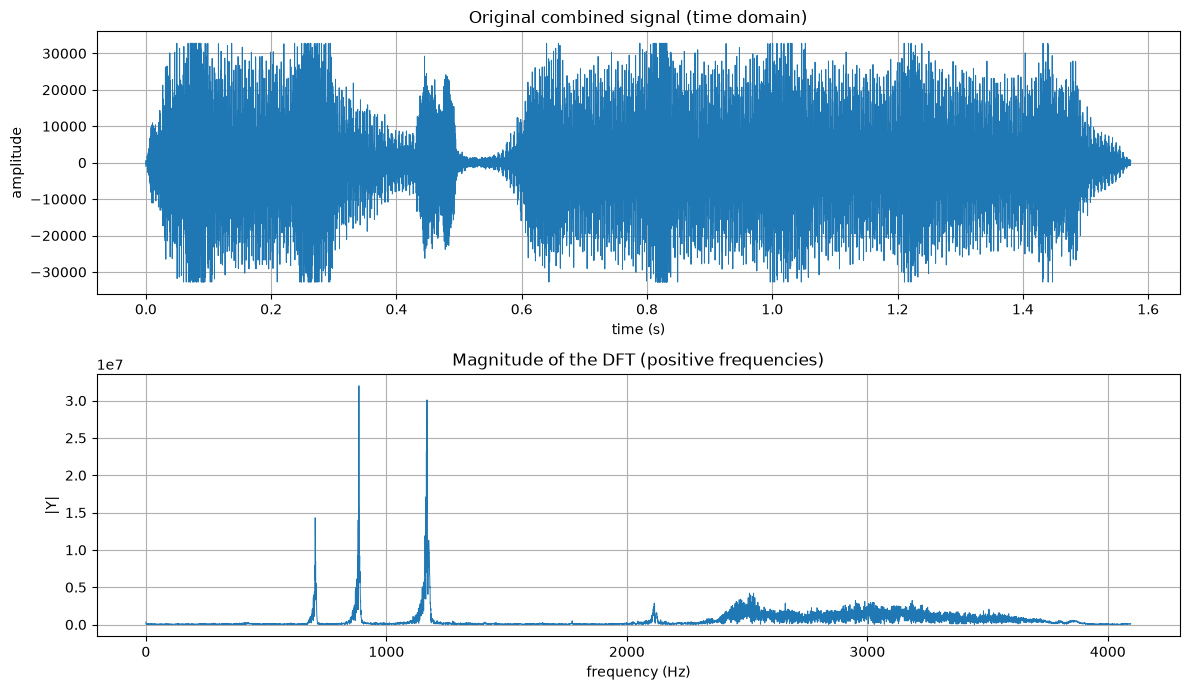

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import scipy.io.wavfile as wav
from IPython.display import Audio, display

plt.rcParams['axes.grid'] = True

Fs, y = wav.read('train_bird.wav')
y = y.astype(float)
N = len(y)
t = np.arange(N) / Fs
Y = np.fft.fft(y)
freq = np.fft.fftfreq(N, 1 / Fs)

print(f'Sampling rate: {Fs} Hz')
print(f'Number of samples: {N}')
print(f'Duration: {N / Fs:.4f} s')

fig, axes = plt.subplots(2, 1, figsize=(12, 7))
axes[0].plot(t, y, linewidth=0.7)
axes[0].set_title('Original combined signal (time domain)')
axes[0].set_xlabel('time (s)')
axes[0].set_ylabel('amplitude')
axes[1].plot(freq[:N // 2], np.abs(Y[:N // 2]), linewidth=0.7)
axes[1].set_title('Magnitude of the DFT (positive frequencies)')
axes[1].set_xlabel('frequency (Hz)')
axes[1].set_ylabel('|Y|')
plt.tight_layout()
plt.savefig('q5_original.png', dpi=150, bbox_inches='tight')
plt.show()

In [2]:
# Construct the filter masks directly from the DFT indices.
# No scipy.signal / numpy filtering routine is used.
def lowpass_mask(N, Fs, cutoff):
    p = int(round(cutoff / (Fs / N)))
    Q = np.ones(N)
    Q[p + 1:N - p] = 0.0
    return Q, p

def highpass_mask(N, Fs, cutoff):
    p = int(round(cutoff / (Fs / N)))
    Q = np.ones(N)
    Q[:p + 1] = 0.0
    Q[N - p:] = 0.0
    return Q, p

cutoff = 2200.0
Q_low, p = lowpass_mask(N, Fs, cutoff)
Q_high, _ = highpass_mask(N, Fs, cutoff)
print(f'Cutoff index p = {p}; actual cutoff = {p * Fs / N:.2f} Hz')
# Conjugate symmetry is Q[k] = Q[N-k], not Q[k] = Q[N-1-k].
print('Low-pass mask conjugate-symmetric:', np.allclose(Q_low, np.roll(Q_low[::-1], 1)))
print('High-pass mask conjugate-symmetric:', np.allclose(Q_high, np.roll(Q_high[::-1], 1)))

Cutoff index p = 3459; actual cutoff = 2200.01 Hz
Low-pass mask conjugate-symmetric: True
High-pass mask conjugate-symmetric: True


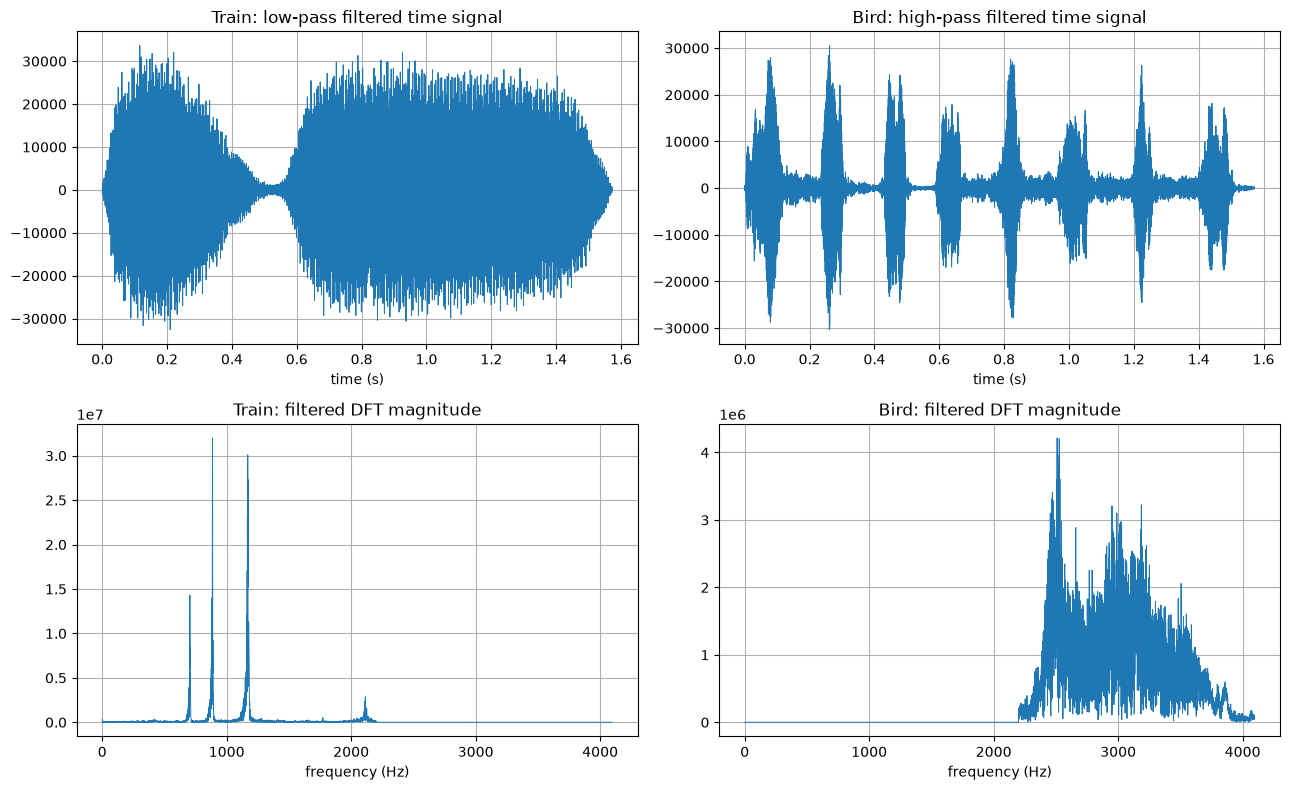

In [3]:
Y_train = Y * Q_low
Y_bird = Y * Q_high
train = np.real(np.fft.ifft(Y_train))
bird = np.real(np.fft.ifft(Y_bird))

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
axes[0, 0].plot(t, train, linewidth=0.7)
axes[0, 0].set_title('Train: low-pass filtered time signal')
axes[0, 0].set_xlabel('time (s)')
axes[0, 1].plot(t, bird, linewidth=0.7)
axes[0, 1].set_title('Bird: high-pass filtered time signal')
axes[0, 1].set_xlabel('time (s)')
axes[1, 0].plot(freq[:N // 2], np.abs(Y_train[:N // 2]), linewidth=0.7)
axes[1, 0].set_title('Train: filtered DFT magnitude')
axes[1, 0].set_xlabel('frequency (Hz)')
axes[1, 1].plot(freq[:N // 2], np.abs(Y_bird[:N // 2]), linewidth=0.7)
axes[1, 1].set_title('Bird: filtered DFT magnitude')
axes[1, 1].set_xlabel('frequency (Hz)')
for ax in axes.flat:
    ax.grid(True)
plt.tight_layout()
plt.savefig('q5_filtered.png', dpi=150, bbox_inches='tight')
plt.show()

Playback of the separated signals:

In [4]:
display(Audio(train, rate=Fs))
display(Audio(bird, rate=Fs))